In [1]:
# IMPORT LIBRARIES

import pandas as pd
import numpy as np

In [2]:
# LOAD DATA
daft = pd.read_csv("daft_housing_data.csv")
rent = pd.read_csv("irish_rent_full.csv")
income = pd.read_csv("disposable_income.csv")

In [3]:
# CLEAN DAFT DATA

# Clean price
daft['Price'] = daft['Price'].astype(str).str.replace('AMV:', '')
daft['Price'] = pd.to_numeric(daft['Price'], errors='coerce')

# Convert numeric columns
daft['Number of Bedrooms'] = pd.to_numeric(daft['Number of Bedrooms'], errors='coerce')
daft['Number of Bathrooms'] = pd.to_numeric(daft['Number of Bathrooms'], errors='coerce')
daft['Floor Area (m2)'] = pd.to_numeric(daft['Floor Area (m2)'], errors='coerce')

# Remove floor area outliers
daft = daft[daft['Floor Area (m2)'] < 1000]

# Drop missing values
daft = daft.dropna(subset=[
    'Price',
    'Number of Bedrooms',
    'Number of Bathrooms',
    'Floor Area (m2)',
    'County'
])

# Standardize county names
daft['County'] = daft['County'].str.strip().str.lower()

# Keep only required columns
daft_clean = daft[['Price', 'Number of Bedrooms',
                   'Number of Bathrooms', 'Floor Area (m2)', 'County']]

In [4]:
# AGGREGATE DAFT DATA
# rent and income data is county level so grouping daft the same way


daft_grouped = daft_clean.groupby('County').agg({
    'Price': 'mean',
    'Number of Bedrooms': 'mean',
    'Number of Bathrooms': 'mean',
    'Floor Area (m2)': 'mean'
}).reset_index()

daft_grouped.rename(columns={
    'Price': 'Avg_Price',
    'Number of Bedrooms': 'Avg_Bedrooms',
    'Number of Bathrooms': 'Avg_Bathrooms',
    'Floor Area (m2)': 'Avg_Floor_Area'
}, inplace=True)

In [5]:
# CLEAN RENT DATA

# Filter and create copy
rent_clean = rent[rent['is_county_aggregate'] == True].copy()

# Clean county names safely
rent_clean.loc[:, 'county'] = rent_clean['county'].str.lower().str.strip()

# Aggregate rent
rent_grouped = rent_clean.groupby('county')['rent_euro'].mean().reset_index()

# Rename columns
rent_grouped.rename(columns={
    'county': 'County',
    'rent_euro': 'Avg_Rent'
}, inplace=True)

In [6]:
# CLEAN INCOME DATA

# Filter and create proper copy
income = income[income['Statistic Label'] == 'Disposable Income per Person'].copy()

# Clean county names safely
income.loc[:, 'County'] = income['County'].str.replace('Co. ', '', regex=False)
income.loc[:, 'County'] = income['County'].str.lower().str.strip()

# Remove Ireland row
income = income[income['County'] != 'ireland'].copy()

# Use latest year
latest_year = income['Year'].max()
income = income[income['Year'] == latest_year].copy()

# Keep required columns
income_clean = income[['County', 'VALUE']].copy()

# Rename column safely
income_clean.rename(columns={'VALUE': 'Avg_Income'}, inplace=True)

In [7]:
# MERGE ALL DATASETS
merged_df = pd.merge(daft_grouped, rent_grouped, on='County', how='inner')
merged_df = pd.merge(merged_df, income_clean, on='County', how='inner')

In [8]:
# CREATE AFFORDABILITY VARIABLES
# price to income ratio - how many years of income needed to buy a property
# ratio above 5 is generally considered unaffordable by international standards
merged_df['Price_to_Income'] = merged_df['Avg_Price'] / merged_df['Avg_Income']
merged_df['Price_to_Rent'] = merged_df['Avg_Price'] / merged_df['Avg_Rent']

In [9]:
# FINAL VALIDATION
print("\nFinal Dataset Preview:")
print(merged_df.head())

print("\nDataset Shape:", merged_df.shape)

print("\nColumn Types:")
print(merged_df.dtypes)

print("\nSummary Statistics:")
print(merged_df.describe())

print("\nDuplicate Counties:", merged_df['County'].duplicated().sum())


Final Dataset Preview:
    County      Avg_Price  Avg_Bedrooms  Avg_Bathrooms  Avg_Floor_Area  \
0   carlow  297350.609756      2.914634       2.060976      125.869268   
1    cavan  251711.078431      2.679739       1.784314      124.564837   
2    clare  244547.032641      2.100890       1.406528       90.311780   
3     cork  408726.334309      2.892465       1.914411      120.768018   
4  donegal  232036.233270      2.445507       1.537285      104.933862   

      Avg_Rent    Avg_Income  Price_to_Income  Price_to_Rent  
0   961.457817  30711.766165         9.681977     309.270573  
1   769.535829  26470.755925         9.509025     327.094684  
2   840.515162  25626.088138         9.542894     290.948984  
3  1195.109018  30748.402383        13.292604     341.999205  
4   673.967309  24685.928712         9.399534     344.284107  

Dataset Shape: (26, 9)

Column Types:
County              object
Avg_Price          float64
Avg_Bedrooms       float64
Avg_Bathrooms      float64
Avg_Fl

In [10]:
# SAVE FINAL DATASET
merged_df.to_csv("FINAL_CLEAN_DATASET.csv", index=False)

print("\n FINAL DATASET SAVED SUCCESSFULLY")


 FINAL DATASET SAVED SUCCESSFULLY


In [11]:
# Import Libraries

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.cluster import KMeans

import xgboost as xgb

In [12]:
# Load Data

county_df = pd.read_csv("FINAL_CLEAN_DATASET.csv")

In [13]:
# BASIC OVERVIEW

print("Shape of dataset:", daft.shape)

print("\nColumns:")
print(daft.columns)

print("\nData Types:")
print(daft.dtypes)

print("\nMissing Values:")
print(daft.isnull().sum())

Shape of dataset: (10506, 14)

Columns:
Index(['Title', 'Price', 'Number of Bedrooms', 'Number of Bathrooms',
       'Property Type', 'Floor Area (m2)', 'BER Rating', 'Latitude',
       'Longitude', 'Listing Views', 'Area', 'County', 'Features',
       'Date of Construction'],
      dtype='object')

Data Types:
Title                    object
Price                   float64
Number of Bedrooms      float64
Number of Bathrooms       int64
Property Type            object
Floor Area (m2)         float64
BER Rating               object
Latitude                float64
Longitude               float64
Listing Views           float64
Area                     object
County                   object
Features                 object
Date of Construction    float64
dtype: object

Missing Values:
Title                      0
Price                      0
Number of Bedrooms         0
Number of Bathrooms        0
Property Type              0
Floor Area (m2)            0
BER Rating              2295
Latit

In [14]:
# # MERGE INTO FULL DAFT

daft = pd.merge(daft, income_clean, on='County', how='inner')
daft = pd.merge(daft, rent_grouped, on='County', how='inner')

print("Merged Shape:", daft.shape)

Merged Shape: (10461, 16)


In [15]:
# CREATE TARGET

daft['Price_to_Income'] = daft['Price'] / daft['Avg_Income']

In [16]:
# DESCRIPTIVE STATISTICS

print("\nSummary Statistics:")
print(daft.describe())


Summary Statistics:
              Price  Number of Bedrooms  Number of Bathrooms  Floor Area (m2)  \
count  1.046100e+04        10461.000000         10461.000000     10461.000000   
mean   4.238689e+05            2.719243             1.811873       115.227458   
std    5.050690e+05            1.800425             1.470805       105.237535   
min    1.250000e+04            0.000000             0.000000         0.000000   
25%    1.800000e+05            2.000000             1.000000        55.000000   
50%    3.250000e+05            3.000000             2.000000       100.000000   
75%    4.950000e+05            4.000000             3.000000       153.000000   
max    1.100000e+07           20.000000            12.000000       990.000000   

           Latitude     Longitude  Listing Views  Date of Construction  \
count  10461.000000  10461.000000   10461.000000           5584.000000   
mean      53.130639     -7.582325    6888.490106           1974.515222   
std        0.772356      1.

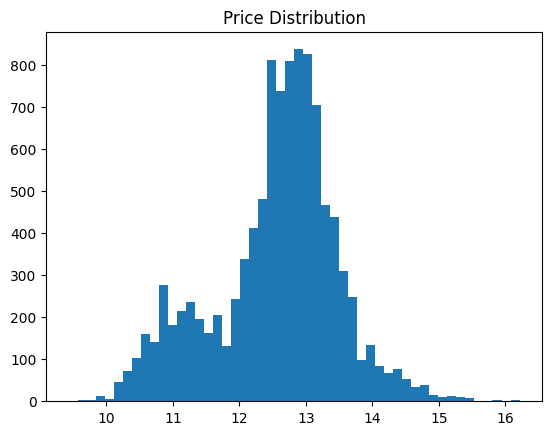

In [17]:
# DISTRIBUTION OF TARGET VARIABLE

daft['Log_Price'] = np.log(daft['Price'])

plt.figure()
plt.hist(daft['Log_Price'], bins=50)
plt.title("Price Distribution")
plt.show()

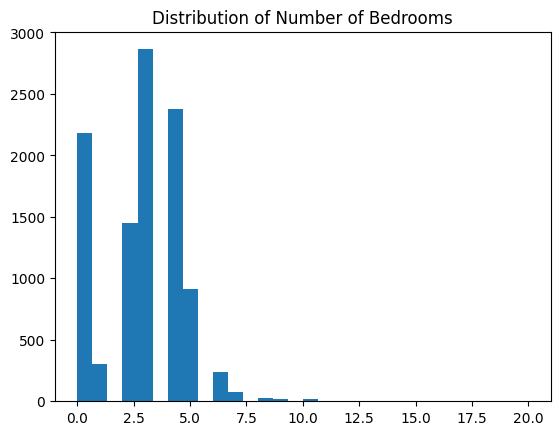

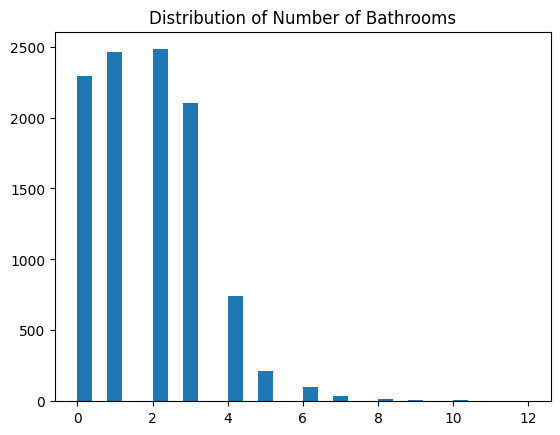

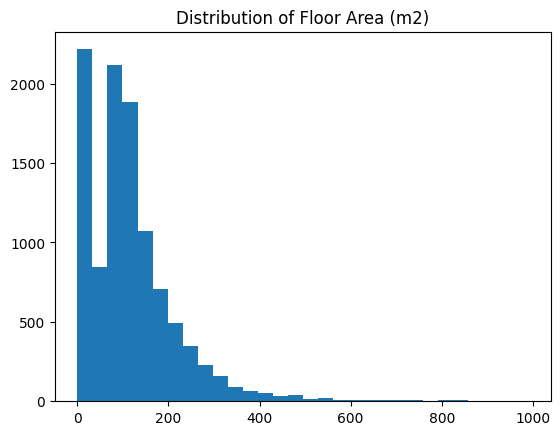

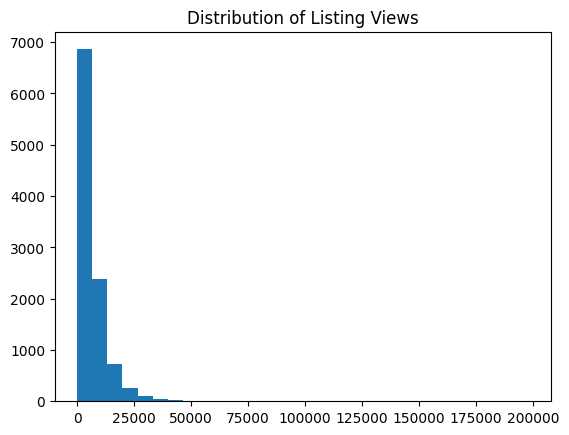

In [18]:
# FEATURE DISTRIBUTIONS

features = [
    'Number of Bedrooms',
    'Number of Bathrooms',
    'Floor Area (m2)',
    'Listing Views'
]

for col in features:
    plt.figure()
    plt.hist(daft[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.show()

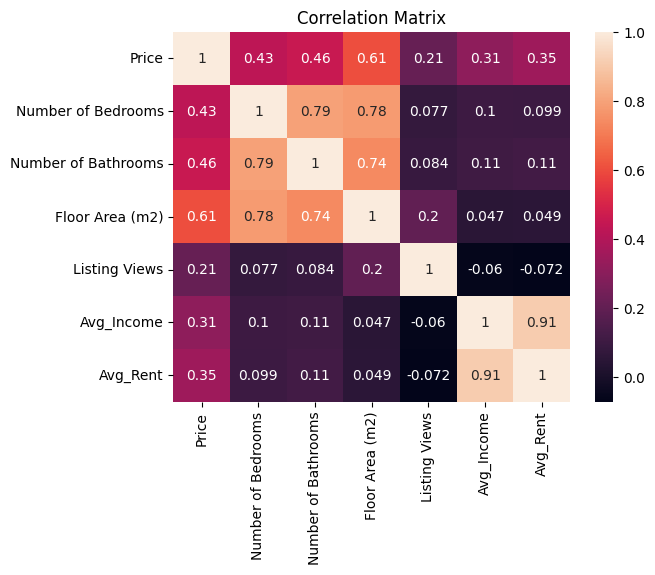

In [19]:
# CORRELATION MATRIX

corr = daft[['Price','Number of Bedrooms','Number of Bathrooms',
             'Floor Area (m2)','Listing Views','Avg_Income','Avg_Rent']].corr()

plt.figure()
sns.heatmap(corr, annot=True)
plt.title("Correlation Matrix")
plt.show()

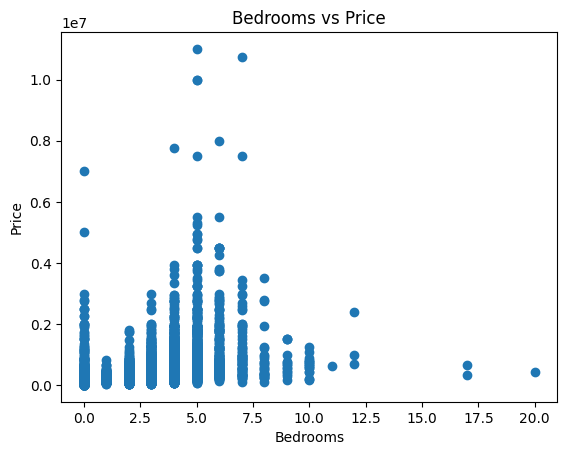

In [20]:
# Bedrooms vs Price

plt.figure()
plt.scatter(daft['Number of Bedrooms'], daft['Price'])
plt.xlabel("Bedrooms")
plt.ylabel("Price")
plt.title("Bedrooms vs Price")
plt.show()

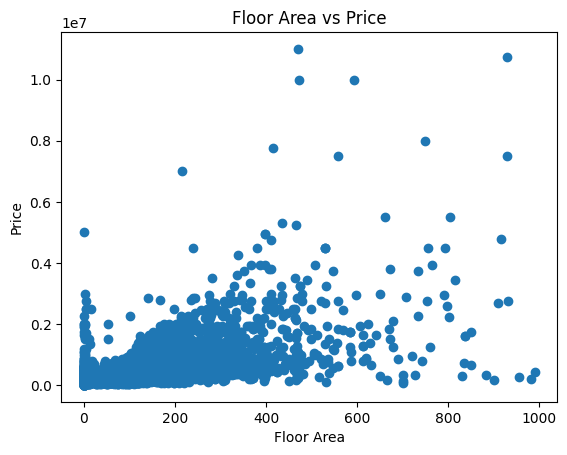

In [21]:
# Floor Area vs Price

plt.figure()
plt.scatter(daft['Floor Area (m2)'], daft['Price'])
plt.xlabel("Floor Area")
plt.ylabel("Price")
plt.title("Floor Area vs Price")
plt.show()

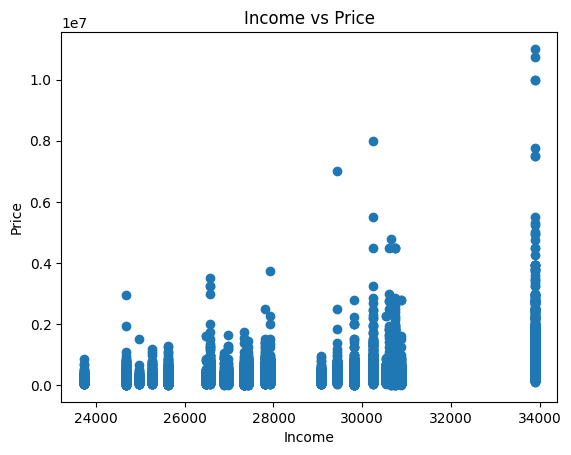

In [22]:
# Income vs Price

plt.figure()
plt.scatter(daft['Avg_Income'], daft['Price'])
plt.xlabel("Income")
plt.ylabel("Price")
plt.title("Income vs Price")
plt.show()

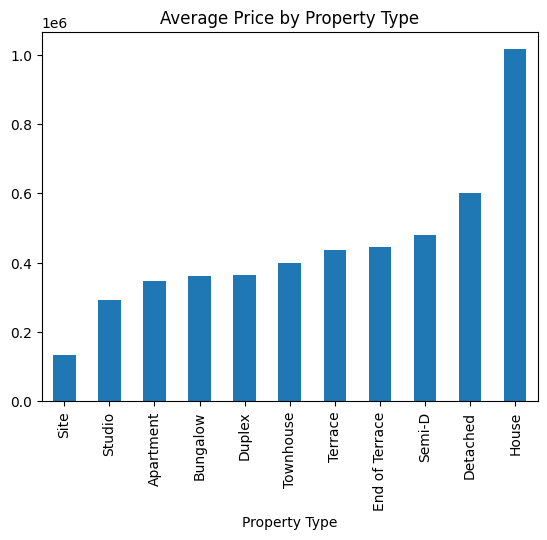

In [23]:
# PROPERTY TYPE ANALYSIS

daft.groupby('Property Type')['Price'].mean().sort_values().plot(kind='bar')

plt.title("Average Price by Property Type")
plt.show()

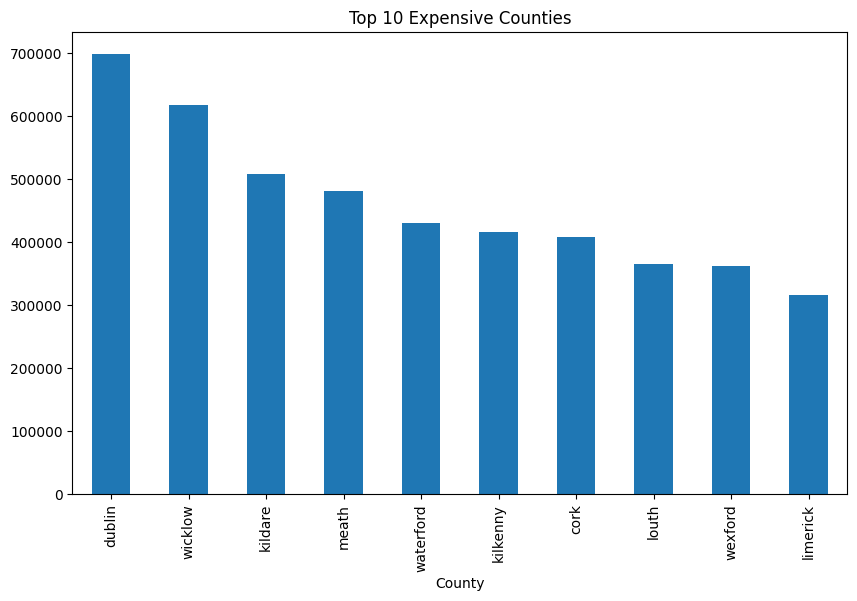

In [24]:
# COUNTY ANALYSIS

county_avg = daft.groupby('County')['Price'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,6))
county_avg.head(10).plot(kind='bar')
plt.title("Top 10 Expensive Counties")
plt.show()

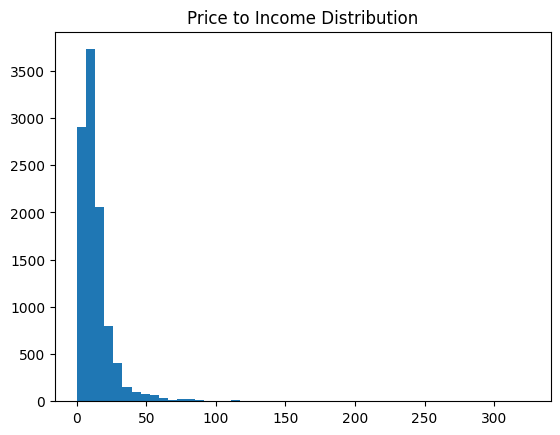

In [25]:
# AFFORDABILITY DISTRIBUTION

plt.figure()
plt.hist(daft['Price_to_Income'], bins=50)
plt.title("Price to Income Distribution")
plt.show()

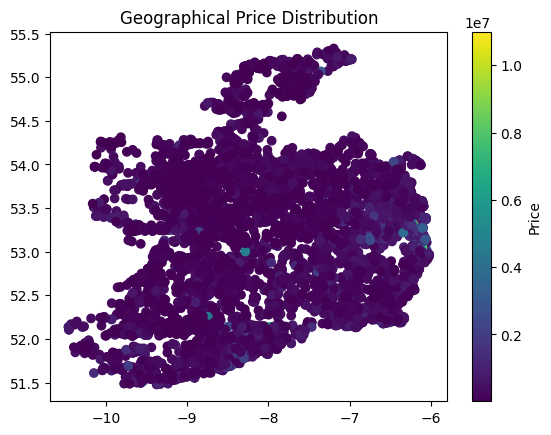

In [26]:
# GEO VISUALIZATION4

plt.figure()
plt.scatter(
    daft['Longitude'],
    daft['Latitude'],
    c=daft['Price'],
)

plt.colorbar(label='Price')
plt.title("Geographical Price Distribution")
plt.show()

In [27]:
# FEATURE ENGINEERING
# selected features based on what drives property prices
# BER and construction date excluded due to too many missing values


le = LabelEncoder()
daft['Property_Type_Encoded'] = le.fit_transform(daft['Property Type'])

features = [
    'Number of Bedrooms',
    'Number of Bathrooms',
    'Floor Area (m2)',
    'Listing Views',
    'Latitude',
    'Longitude',
    'Property_Type_Encoded',
    'Avg_Income',
    'Avg_Rent'
]

X = daft[features]
y = daft['Price_to_Income']

In [28]:
# TRAIN TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [29]:
# SCALING

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [30]:
# Linear Regression Model

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

In [31]:
rf = RandomForestRegressor(
    n_estimators=150,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [32]:
# XGBoost Model
from sklearn.model_selection import RandomizedSearchCV

xgbr = xgb.XGBRegressor(objective='reg:squarederror', n_jobs=-1)

param_xgb = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1],
    'colsample_bytree': [0.8, 1]
}

random_xgb = RandomizedSearchCV(
    xgbr,
    param_distributions=param_xgb,
    n_iter=10,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    random_state=42
)

random_xgb.fit(X_train, y_train)

xgb_best = random_xgb.best_estimator_
xgb_pred = xgb_best.predict(X_test)

In [33]:
# SVM Model

from sklearn.svm import LinearSVR

svm = SVR(kernel='rbf', C=10, epsilon=0.1)
svm.fit(X_train_scaled, y_train)
svm_pred = svm.predict(X_test_scaled)

In [34]:
# EVALUATION OF MODELS

def evaluate(name, y_test, pred):
    print(f"\n{name}")
    print("MAE:", mean_absolute_error(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
    print("R2:", r2_score(y_test, pred))

evaluate("Linear Regression", y_test, lr_pred)
evaluate("Random Forest", y_test, rf_pred)
evaluate("XGBoost", y_test, xgb_pred)
evaluate("SVM", y_test, svm_pred)


Linear Regression
MAE: 5.196213268763484
RMSE: 9.807276107135614
R2: 0.47858285341387774

Random Forest
MAE: 3.2882897791642365
RMSE: 7.505112990423107
R2: 0.6946464495519933

XGBoost
MAE: 3.3631322020593566
RMSE: 7.380556724038154
R2: 0.7046977548464335

SVM
MAE: 3.677610787651037
RMSE: 8.72072484444871
R2: 0.5877186667204071


In [35]:
# CROSS VALIDATION
# xgboost came out best in the evaluation above so running cv on it
# to make sure it generalises and isn't just overfitting the training split


from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=10, shuffle=True, random_state=42)

scores = cross_val_score(xgb_best, X, y, cv=kf, scoring='r2')

print("XGBoost 10-Fold R2:", scores.mean())

XGBoost 10-Fold R2: 0.7222159987164699


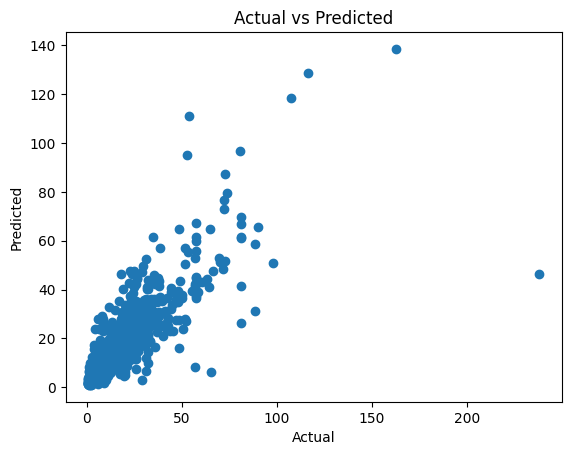

In [36]:
# ACTUAL VS PREDICTED

plt.figure()
plt.scatter(y_test, xgb_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

In [45]:
# CLUSTERING
# k=3 chosen to split counties into low, moderate and high affordability groups


cluster_data = county_df[['Price_to_Income','Price_to_Rent']]

kmeans = KMeans(n_clusters=3, random_state=42)
county_df['Cluster'] = kmeans.fit_predict(cluster_data)
print(county_df.groupby('Cluster')[['Price_to_Income','Price_to_Rent']].mean())

         Price_to_Income  Price_to_Rent
Cluster                                
0              16.217828     431.076078
1              11.341460     327.299747
2               8.583809     253.734221


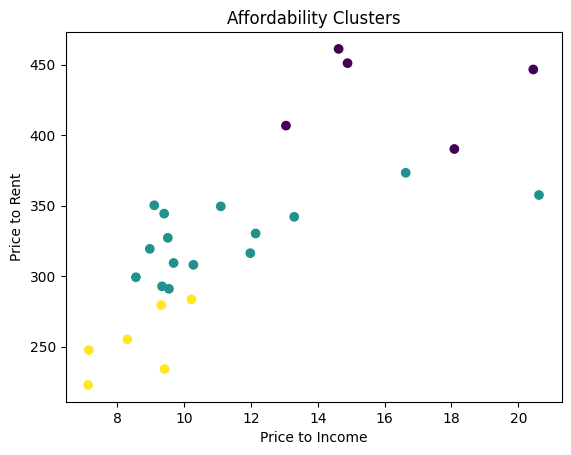

In [38]:
# CLUSTER VISUAL

plt.figure()
plt.scatter(
    county_df['Price_to_Income'],
    county_df['Price_to_Rent'],
    c=county_df['Cluster']
)
plt.title("Affordability Clusters")
plt.xlabel("Price to Income")
plt.ylabel("Price to Rent")
plt.show()

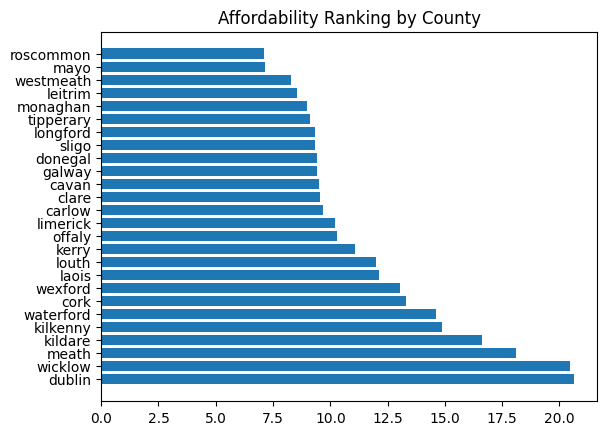

In [39]:
# COUNTY RANKING

county_sorted = county_df.sort_values(by='Price_to_Income', ascending=False)

plt.figure()
plt.barh(county_sorted['County'], county_sorted['Price_to_Income'])
plt.title("Affordability Ranking by County")
plt.show()

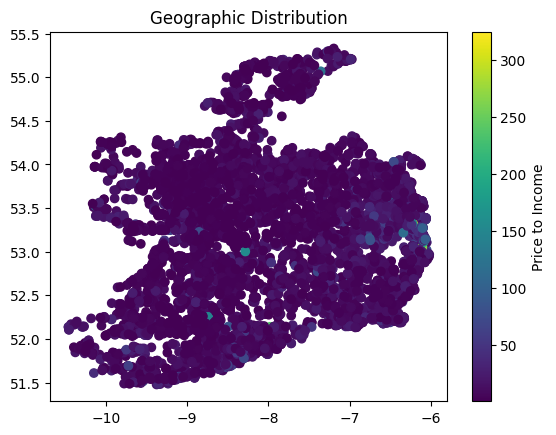

In [40]:
# GEOGRAPHIC VISUAL

plt.figure()
plt.scatter(
    daft['Longitude'],
    daft['Latitude'],
    c=daft['Price_to_Income']
)
plt.colorbar(label='Price to Income')
plt.title("Geographic Distribution")
plt.show()

In [41]:
# SUMMARY

print("\nTop Least Affordable Counties:")
print(county_df.sort_values(by='Price_to_Income', ascending=False).head())

print("\nMost Affordable Counties:")
print(county_df.sort_values(by='Price_to_Income').head())


Top Least Affordable Counties:
      County      Avg_Price  Avg_Bedrooms  Avg_Bathrooms  Avg_Floor_Area  \
5     dublin  698754.965504      2.954772       2.020698      120.707949   
25   wicklow  618251.436031      3.096606       2.078329      138.236632   
16     meath  480625.000000      2.983051       2.105932      134.967034   
8    kildare  509081.313131      3.212121       2.356902      140.897845   
9   kilkenny  415538.613861      3.049505       2.029703      150.243762   

       Avg_Rent    Avg_Income  Price_to_Income  Price_to_Rent  Cluster  
5   1954.662198  33889.006451        20.618927     357.481188        1  
25  1384.662772  30235.138896        20.448110     446.499645        0  
16  1232.019158  26574.986564        18.085616     390.111628        0  
8   1363.951948  30611.545921        16.630369     373.239918        1  
9    921.386905  27910.245649        14.888390     450.992533        0  

Most Affordable Counties:
       County      Avg_Price  Avg_Bedrooms  Av

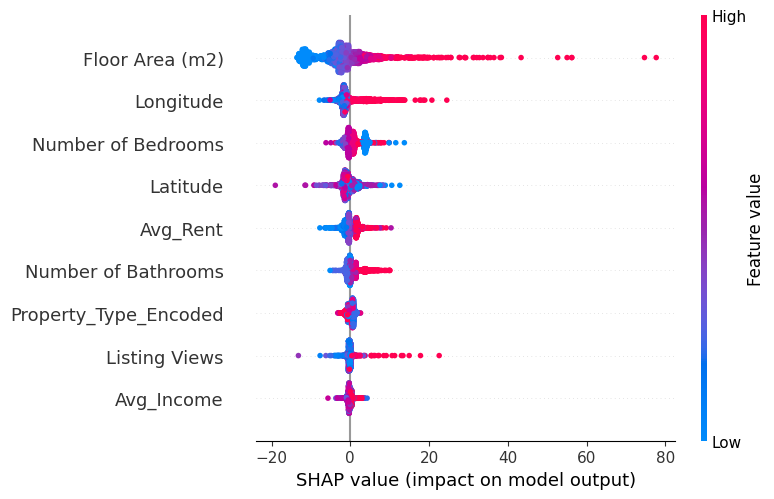

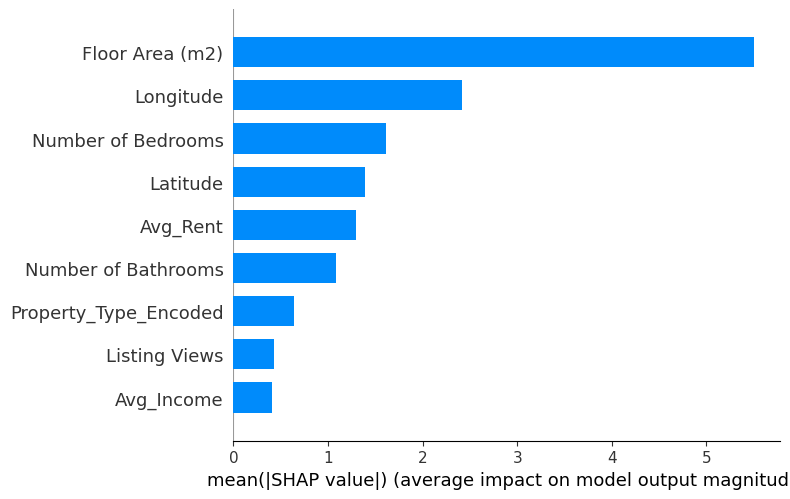

In [42]:
import shap

explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)
shap.summary_plot(shap_values, X_test, plot_type="bar")